In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.astype(int)

feature_names = df.drop("target", axis=1).columns

print("Dataset Shape:", df.shape)
print("\nTarget Distribution:")
print(df["target"].value_counts())

Dataset Shape: (302, 14)

Target Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [3]:
def train_test_split_manual(X, y, test_size=0.2, seed=42):

    np.random.seed(seed)

    train_idx, test_idx = [], []

    for cls in np.unique(y):
        indices = np.where(y == cls)[0]
        np.random.shuffle(indices)

        split = int(len(indices) * (1 - test_size))

        train_idx.extend(indices[:split])
        test_idx.extend(indices[split:])

    train_idx = np.array(train_idx)
    test_idx = np.array(test_idx)

    np.random.shuffle(train_idx)
    np.random.shuffle(test_idx)

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


X_train, X_test, y_train, y_test = train_test_split_manual(X, y)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (241, 13)
Testing Data: (61, 13)


In [4]:
def sigmoid(x):
    x = np.clip(x, -15, 15)
    return 1 / (1 + np.exp(-x))


def calculate_gradient_hessian(y, predictions):

    probabilities = sigmoid(predictions)

    gradients = probabilities - y
    hessians = probabilities * (1 - probabilities)

    return gradients, hessians

In [5]:
def calculate_gain(G_left, H_left, G_right, H_right,
                   G_total, H_total, reg_lambda=1):

    left_score = (G_left ** 2) / (H_left + reg_lambda)
    right_score = (G_right ** 2) / (H_right + reg_lambda)
    parent_score = (G_total ** 2) / (H_total + reg_lambda)

    return 0.5 * (left_score + right_score - parent_score)

In [6]:
def build_boost_tree(X, gradients, hessians, depth=0,
                     max_depth=2, reg_lambda=1, min_child_weight=1):

    G = np.sum(gradients)
    H = np.sum(hessians)

    leaf_value = -G / (H + reg_lambda)

    if depth >= max_depth or len(X) < 2:
        return leaf_value

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(X.shape[1]):

        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:

            left = X[:, feature] <= threshold
            right = ~left

            G_left = np.sum(gradients[left])
            H_left = np.sum(hessians[left])
            G_right = np.sum(gradients[right])
            H_right = np.sum(hessians[right])

            if H_left < min_child_weight or H_right < min_child_weight:
                continue

            gain = calculate_gain(
                G_left, H_left, G_right, H_right, G, H, reg_lambda
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    if best_feature is None:
        return leaf_value

    left = X[:, best_feature] <= best_threshold
    right = ~left

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "gain": best_gain,
        "left": build_boost_tree(
            X[left], gradients[left], hessians[left],
            depth + 1, max_depth, reg_lambda, min_child_weight
        ),
        "right": build_boost_tree(
            X[right], gradients[right], hessians[right],
            depth + 1, max_depth, reg_lambda, min_child_weight
        )
    }

In [7]:
def predict_boost_tree(tree, row):

    while isinstance(tree, dict):

        if row[tree["feature"]] <= tree["threshold"]:
            tree = tree["left"]
        else:
            tree = tree["right"]

    return tree

In [8]:
def train_xgboost(X, y, n_estimators=30, learning_rate=0.1,
                  max_depth=2, reg_lambda=1):

    base_probability = np.clip(np.mean(y), 1e-5, 1 - 1e-5)
    base_score = np.log(base_probability / (1 - base_probability))

    predictions = np.full(len(y), base_score, dtype=float)

    trees = []
    importance = np.zeros(X.shape[1])

    for _ in range(n_estimators):

        gradients, hessians = calculate_gradient_hessian(y, predictions)

        tree = build_boost_tree(
            X, gradients, hessians,
            max_depth=max_depth,
            reg_lambda=reg_lambda
        )

        trees.append(tree)

        predictions += learning_rate * np.array([
            predict_boost_tree(tree, row) for row in X
        ])

    def collect_importance(tree):

        if not isinstance(tree, dict):
            return

        importance[tree["feature"]] += tree["gain"]

        collect_importance(tree["left"])
        collect_importance(tree["right"])

    for tree in trees:
        collect_importance(tree)

    if importance.sum() > 0:
        importance /= importance.sum()

    return base_score, trees, importance


base_score, boost_trees, xgb_importance = train_xgboost(
    X_train, y_train,
    n_estimators=30,
    learning_rate=0.1,
    max_depth=2
)

print("Total Weak Learners:", len(boost_trees))

Total Weak Learners: 30


In [9]:
def predict_xgboost(X, base_score, trees, learning_rate=0.1):

    predictions = np.full(len(X), base_score, dtype=float)

    for tree in trees:

        tree_predictions = np.array([
            predict_boost_tree(tree, row) for row in X
        ])

        predictions += learning_rate * tree_predictions

    probabilities = sigmoid(predictions)

    return (probabilities >= 0.5).astype(int)


xgb_predictions = predict_xgboost(
    X_test, base_score, boost_trees
)

print("Actual Values:   ", y_test[:10])
print("Predicted Values:", xgb_predictions[:10])

Actual Values:    [0 0 0 0 0 0 1 0 1 0]
Predicted Values: [0 1 0 1 1 0 1 0 1 0]


In [10]:
correct = 0

for actual, predicted in zip(y_test, xgb_predictions):

    if actual == predicted:
        correct += 1

xgb_accuracy = correct / len(y_test) * 100

print("Gradient Boosting Accuracy:", round(xgb_accuracy, 2), "%")

Gradient Boosting Accuracy: 77.05 %


In [11]:
def gini(y):

    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)

    return 1 - np.sum(p ** 2)


def build_rf_tree(X, y, depth=0, max_depth=8, importance=None):

    classes, counts = np.unique(y, return_counts=True)
    prediction = classes[np.argmax(counts)]

    if len(classes) == 1 or depth >= max_depth or len(y) < 4:
        return prediction

    features = np.random.choice(
        X.shape[1],
        max(1, int(np.sqrt(X.shape[1]))),
        replace=False
    )

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in features:

        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:

            left = X[:, feature] <= threshold
            right = ~left

            if not left.any() or not right.any():
                continue

            weighted = (
                left.sum() * gini(y[left]) +
                right.sum() * gini(y[right])
            ) / len(y)

            gain = gini(y) - weighted

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    if best_feature is None:
        return prediction

    left = X[:, best_feature] <= best_threshold
    right = ~left

    importance[best_feature] += best_gain * len(y)

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_rf_tree(X[left], y[left], depth + 1, max_depth, importance),
        "right": build_rf_tree(X[right], y[right], depth + 1, max_depth, importance)
    }


def predict_rf_tree(tree, row):

    while isinstance(tree, dict):

        if row[tree["feature"]] <= tree["threshold"]:
            tree = tree["left"]
        else:
            tree = tree["right"]

    return tree


def train_rf(X, y, n_trees=25):

    forest = []
    importance = np.zeros(X.shape[1])

    for _ in range(n_trees):

        indices = np.random.choice(len(X), len(X), replace=True)

        tree = build_rf_tree(
            X[indices], y[indices], importance=importance
        )

        forest.append(tree)

    if importance.sum() > 0:
        importance /= importance.sum()

    return forest, importance


np.random.seed(42)

rf_forest, rf_importance = train_rf(X_train, y_train)

print("Random Forest Trees:", len(rf_forest))

Random Forest Trees: 25


In [12]:
def predict_rf(forest, X):

    predictions = []

    for row in X:

        votes = [predict_rf_tree(tree, row) for tree in forest]

        classes, counts = np.unique(votes, return_counts=True)

        predictions.append(classes[np.argmax(counts)])

    return np.array(predictions)


rf_predictions = predict_rf(rf_forest, X_test)

rf_correct = sum(
    actual == predicted
    for actual, predicted in zip(y_test, rf_predictions)
)

rf_accuracy = rf_correct / len(y_test) * 100

print("Random Forest Accuracy:", round(rf_accuracy, 2), "%")

Random Forest Accuracy: 75.41 %


,Model,Accuracy (%)
0,Random Forest,75.409836
1,Gradient Boosting,77.049180


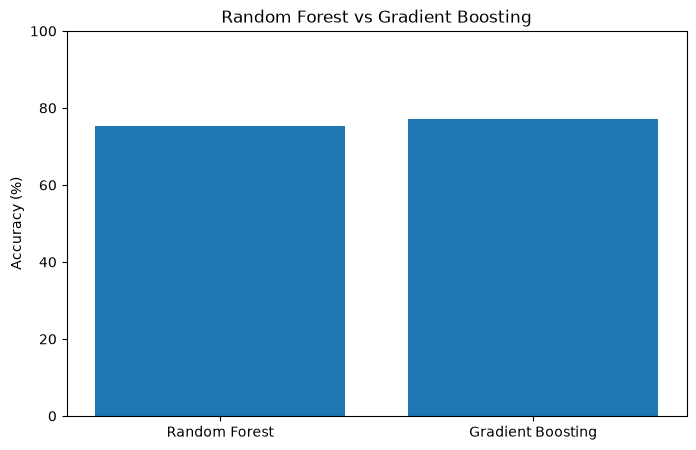

In [13]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Gradient Boosting"],
    "Accuracy (%)": [rf_accuracy, xgb_accuracy]
})

display(comparison)

plt.figure(figsize=(8, 5))

plt.bar(comparison["Model"], comparison["Accuracy (%)"])

plt.title("Random Forest vs Gradient Boosting")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

,Feature,Random Forest,Gradient Boosting
2,cp,0.142909,0.370288
12,thal,0.103008,0.168078
11,ca,0.120791,0.152367
7,thalach,0.114937,0.072177
9,oldpeak,0.114979,0.068790
8,exang,0.097014,0.053090
1,sex,0.048375,0.041843
0,age,0.069610,0.031291
10,slope,0.020076,0.018707
6,restecg,0.024605,0.012928


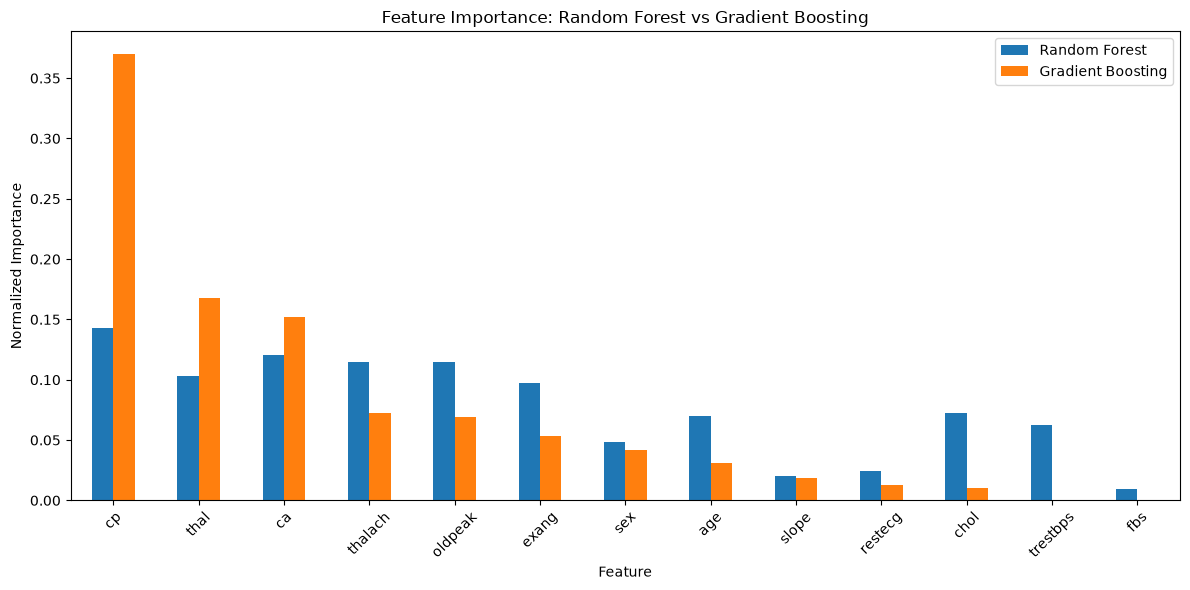

In [14]:
importance_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Random Forest": rf_importance,
    "Gradient Boosting": xgb_importance
})

importance_comparison = importance_comparison.sort_values(
    "Gradient Boosting", ascending=False
)

display(importance_comparison)

importance_comparison.set_index("Feature").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Feature Importance: Random Forest vs Gradient Boosting")
plt.ylabel("Normalized Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Conclusion

In this task, a Gradient Boosting model was implemented manually using
weak regression trees, gradients, hessians, and gain-based splitting.

The model was trained iteratively, where each new tree attempted to
correct the errors made by previous predictions.

Its performance was compared with a manually implemented Random Forest
using test accuracy.

Feature importance from both models was also compared to identify
differences in the features used for prediction.

This implementation demonstrates the core concepts of XGBoost-style
gradient boosting without using scikit-learn or the XGBoost library.